# Bab 4 — Introduction to neural learning: gradient descent

**Mahasiswa:** Tarannia Raisha Putri · 101032300231 · TK4702 · Deep Learning

**Referensi utama:** Andrew W. Trask, *Grokking Deep Learning*, Manning (2019), Bab 4, halaman cetak 47–77 (PDF 68–98, indeks PDF mulai 1). Subbab spesifik dicantumkan pada setiap tahap.

**Tujuan pembelajaran:** Menurunkan gradien satu bobot, menelusuri satu pembaruan, dan menjelaskan syarat stabilitas.

## Ringkasan

Belajar dimulai dengan mengukur kesalahan prediksi. Buku membandingkan pencarian hot-and-cold dengan gradient descent, lalu menunjukkan overshoot, divergence, dan peran learning rate alpha.

## Konsep, intuisi, dan notasi

Buku menampilkan squared error $E=(xw-y)^2$, tetapi update menggunakan $x(xw-y)$, yakni turunan $L=\tfrac12(xw-y)^2$. Faktor 2 dapat diserap ke learning rate; jangan mencampur dua definisi saat gradient checking.

$\delta=\hat y-y$, $\frac{\partial L}{\partial w}=x\delta$, $w_{t+1}=w_t-\alpha x\delta$. Semua variabel di sini skalar. Delta node menyatakan perubahan terhadap prediksi; gradien bobot juga bergantung pada seberapa besar input berkontribusi.

Untuk satu titik dengan $x\ne0$, optimum $w^*=y/x$. Error bobot mengikuti $w_{t+1}-w^*=(1-\alpha x^2)(w_t-w^*)$. Konvergensi membutuhkan $0<\alpha x^2<2$. Input besar dapat menyebabkan overshoot walau alpha tidak berubah. Turunan adalah sensitivitas lokal, bukan janji bahwa langkah berukuran sembarang selalu memperbaiki loss.

## Persiapan dan cara membaca

Jalankan **Restart Kernel → Run All**. Semua penjelasan merupakan parafrasa orisinal; angka hasil berada pada output sel yang benar-benar dijalankan. Label **reproduksi** berarti algoritme/contoh buku ditulis ulang; **koreksi/penyesuaian** menunjukkan perubahan; **tambahan** menunjukkan eksperimen atau interpretasi praktikum. `GDL_MODE=quick` mengurangi latihan berat; `full` memilih anggaran buku, dengan perubahan yang tetap dicatat. Keberhasilan eksekusi tidak membuktikan kesamaan akurasi dengan buku.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Jalankan dari root repository atau notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MODE = os.environ.get('GDL_MODE', 'quick')
assert MODE in {'quick', 'full'}
FULL = MODE == 'full'
np.random.seed(1)
np.set_printoptions(precision=6, suppress=True)
METRICS = {}
def record(**values):
    METRICS.update(values)
def finite(*arrays):
    assert all(np.isfinite(np.asarray(a)).all() for a in arrays), 'NaN/inf terdeteksi'
def softmax(z):
    z = np.asarray(z)
    e = np.exp(z - np.max(z, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)
def sigmoid(z):
    return np.exp(-np.logaddexp(0, -np.asarray(z)))
print('Mode:', MODE, '| NumPy:', np.__version__)

Mode: quick | NumPy: 2.5.4


<a id="b04-compare"></a>

## Reproduksi: compare, hot-and-cold

**Sumber:** cetak 48–55; PDF 69–76.

Hitung error pada bobot awal serta bobot sedikit naik/turun, lalu pilih arah yang lebih baik. Metode ini memerlukan evaluasi berulang dan langkah tetap dapat lambat atau berosilasi dekat optimum. Output panjang 1.101 langkah diringkas tanpa mengurangi jumlah update.

In [2]:
print('Squared error awal:',(.5*.5-.8)**2)
for weight in [.1,.11,.09]:
    print('weight=',weight,'prediction=',8.5*weight,'error=',(8.5*weight-1)**2)
w=.5; history=[]
for step in range(1101):
    history.append((.5*w-.8)**2)
    up=(.5*(w+.001)-.8)**2; down=(.5*(w-.001)-.8)**2
    if down<up: w-=.001
    elif up<down: w+=.001
print('Hot/cold: awal, akhir, bobot:',history[0],history[-1],w)
assert history[-1]<history[0]

Squared error awal: 0.30250000000000005
weight= 0.1 prediction= 0.8500000000000001 error= 0.022499999999999975
weight= 0.11 prediction= 0.935 error= 0.004224999999999993
weight= 0.09 prediction= 0.765 error= 0.055224999999999996
Hot/cold: awal, akhir, bobot: 0.30250000000000005 1.0799505792475652e-27 1.6009999999999343


<a id="b04-gradient"></a>

## Reproduksi: delta, derivative, dan satu update

**Sumber:** cetak 56–71; PDF 77–92.

Input ikut mengalikan delta karena bobot yang sama berdampak lebih besar saat input besar. Bila input nol, perubahan bobot itu tidak dapat mengubah output sehingga gradiennya nol. Analogi kemiringan mangkuk dan batang pada buku merujuk pada hubungan terikat antara bobot, prediksi, dan error.

In [3]:
x,y,w,alpha=8.5,1.,.1,.01
pred=x*w; delta=pred-y; weight_delta=x*delta
print({'prediction':pred,'error':delta**2,'node_delta':delta,'weight_delta':weight_delta,'new_weight':w-alpha*weight_delta})
def descent(x,y,w,alpha,steps):
    trace=[]
    for t in range(steps):
        pred=x*w; delta=pred-y; grad=x*delta
        trace.append([w,pred,delta**2,grad])
        w-=alpha*grad
    return w,np.array(trace)
for x,w,steps in [(.5,.5,20),(.5,0.,4),(1.1,0.,4)]:
    final,trace=descent(x,.8,w,1.,steps)
    print('x=',x,'[w,pred,error,gradient]:\n',trace[:4], '\nerror terakhir:',trace[-1,2])
# Tambahan: finite difference pada half squared error.
x,y,w=1.1,.8,.3; eps=1e-6
numeric=(.5*(x*(w+eps)-y)**2-.5*(x*(w-eps)-y)**2)/(2*eps)
analytic=x*(x*w-y)
np.testing.assert_allclose(numeric,analytic,atol=1e-9)
record(gradient_check_abs_error=abs(numeric-analytic))

{'prediction': 0.8500000000000001, 'error': 0.022499999999999975, 'node_delta': -0.1499999999999999, 'weight_delta': -1.2749999999999992, 'new_weight': 0.11275}
x= 0.5 [w,pred,error,gradient]:
 [[ 0.5       0.25      0.3025   -0.275   ]
 [ 0.775     0.3875    0.170156 -0.20625 ]
 [ 0.98125   0.490625  0.095713 -0.154688]
 [ 1.135938  0.567969  0.053839 -0.116016]] 
error terakhir: 5.408208020258491e-06
x= 0.5 [w,pred,error,gradient]:
 [[ 0.        0.        0.64     -0.4     ]
 [ 0.4       0.2       0.36     -0.3     ]
 [ 0.7       0.35      0.2025   -0.225   ]
 [ 0.925     0.4625    0.113906 -0.16875 ]] 
error terakhir: 0.11390625000000001
x= 1.1 [w,pred,error,gradient]:
 [[ 0.        0.        0.64     -0.88    ]
 [ 0.88      0.968     0.028224  0.1848  ]
 [ 0.6952    0.76472   0.001245 -0.038808]
 [ 0.734008  0.807409  0.000055  0.00815 ]] 
error terakhir: 5.4890317439999896e-05


<a id="b04-divergence"></a>

## Reproduksi: breaking gradient descent dan alpha

**Sumber:** cetak 72–77; PDF 93–98.

Dengan x=2 dan alpha=1, multiplier error bobot adalah −3 sehingga magnitudenya membesar. Mengurangi alpha menjadi 0,1 mengubah multiplier menjadi 0,6. Divergence sengaja dipertahankan sebagai pelajaran; hasilnya tetap finite pada 20 langkah.

Divergen: [4.000000e-02 5.403407e+16] | stabil: [0.04 0.  ]


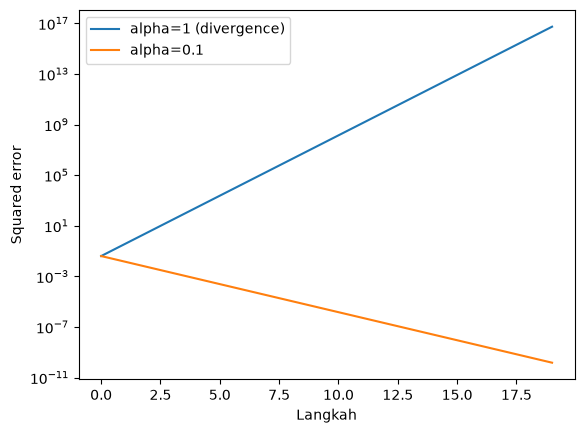

In [4]:
_,bad=descent(2.,.8,.5,1.,20)
_,good=descent(2.,.8,.5,.1,20)
finite(bad,good)
assert bad[-1,2]>bad[0,2] and good[-1,2]<good[0,2]
print('Divergen:',bad[[0,-1],2], '| stabil:',good[[0,-1],2])
plt.semilogy(bad[:,2],label='alpha=1 (divergence)')
plt.semilogy(good[:,2],label='alpha=0.1')
plt.xlabel('Langkah'); plt.ylabel('Squared error'); plt.legend(); plt.show()
record(divergent_final_error=float(bad[-1,2]),stable_final_error=float(good[-1,2]))

## Analisis output aktual — run tersimpan

Mode **quick**, eksekusi 2026-10-16T01:50:12.177506+07:00. Ringkasan ini dibuat dari output validator, bukan angka contoh dalam buku.

Alpha besar menghasilkan squared error akhir 5.403e+16, sedangkan alpha kecil menghasilkan 1.485e-10. Divergence adalah hasil yang sengaja didemonstrasikan, bukan kegagalan validasi. Selisih gradien numerik 1.539e-11.

## Kesimpulan dan pembahasan pertanyaan

Kegagalan alpha besar bukan error program: gradien lokal benar, tetapi langkah terlalu jauh. Gradient check menguji rumus, sedangkan kurva loss menunjukkan perilaku iterasi.

**Mengapa arah minus?** Gradien menunjuk kenaikan tercepat loss; arah negatif menurunkannya untuk langkah cukup kecil.

**Mengapa loss buku dan gradien tampak berbeda faktor 2?** Update setara dengan half squared error atau penyerapan faktor ke alpha.

**Apakah loss nol pada satu titik membuktikan generalisasi?** Tidak; itu hanya cocok dengan titik yang dilatih.

In [5]:
finite(*[v for v in METRICS.values() if isinstance(v, (int, float))])
print('VALIDATION_METRICS=' + json.dumps(METRICS, sort_keys=True))

VALIDATION_METRICS={"divergent_final_error": 5.403406870691965e+16, "gradient_check_abs_error": 1.5387024987489895e-11, "stable_final_error": 1.485277170987127e-10}
